In [9]:
import os
import shutil
import random
from sklearn.model_selection import train_test_split

# Исходные папки
POSITIVE_DIR = 'positive'   # изображения с куклами (класс 1)
NEGATIVE_DIR = 'negative'   # изображения без кукол (класс 0)
OUTPUT_DATASET = 'dataset'  # итоговая структура

# Собираем все файлы и метки
all_files = []
all_labels = []

for folder, label in [(POSITIVE_DIR, 1), (NEGATIVE_DIR, 0)]:
    for fname in os.listdir(folder):
        if fname.lower().endswith(('.jpg', '.jpeg', '.png')):
            all_files.append(os.path.join(folder, fname))
            all_labels.append(label)

# Разделяем: 70% train, 15% val, 15% test
X_train, X_temp, y_train, y_temp = train_test_split(
    all_files, all_labels, test_size=0.3, random_state=42, stratify=all_labels
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

# Создаём структуру папок
for split in ['train', 'validation', 'test']:
    for cls in ['cow', 'landscape']:  # cow = кукла, landscape = не кукла (можно переименовать)
        os.makedirs(os.path.join(OUTPUT_DATASET, split, cls), exist_ok=True)

# Функция копирования
def copy_files(file_list, label_list, split):
    for filepath, label in zip(file_list, label_list):
        cls_folder = 'cow' if label == 1 else 'landscape'
        dst = os.path.join(OUTPUT_DATASET, split, cls_folder, os.path.basename(filepath))
        shutil.copy2(filepath, dst)

copy_files(X_train, y_train, 'train')
copy_files(X_val, y_val, 'validation')
copy_files(X_test, y_test, 'test')

print(f"Train: {len(X_train)}, Validation: {len(X_val)}, Test: {len(X_test)}")

Train: 147, Validation: 32, Test: 32


Found 147 files belonging to 2 classes.
Found 32 files belonging to 2 classes.
Found 32 files belonging to 2 classes.
Классы: ['cow', 'landscape']


d:\Repositories\Study-projects\Data_analysis_with_Python\venv\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     6,422,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,516,289 (24.86 MB)

 Trainable params: 6,516,289 (24.86 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15


d:\Repositories\Study-projects\Data_analysis_with_Python\venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 112ms/step - accuracy: 0.5510 - loss: 1.0156 - val_accuracy: 0.5312 - val_loss: 0.7095
Epoch 2/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 84ms/step - accuracy: 0.5238 - loss: 0.6733 - val_accuracy: 0.5312 - val_loss: 0.6703
Epoch 3/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.5442 - loss: 0.6849 - val_accuracy: 0.5625 - val_loss: 0.6525
Epoch 4/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.6122 - loss: 0.6208 - val_accuracy: 0.5625 - val_loss: 0.6297
Epoch 5/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.7143 - loss: 0.5603 - val_accuracy: 0.6250 - val_loss: 0.5850
Epoch 6/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.8299 - loss: 0.4551 - val_accuracy: 0.6250 - val_loss: 0.5695
Epoch 7/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.8571 - loss: 0.3825 - val_accuracy: 0.6250 - val_loss: 0.6684
Epoch 8/15
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.8571 - loss: 0.4009 - val_accuracy: 0.6875 - val_loss: 0.6602
Epoch 9/15

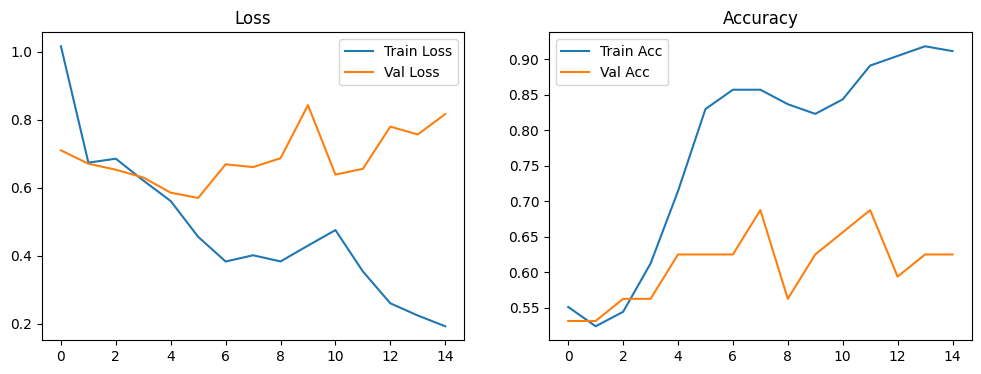

In [10]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import os

# 1. Загрузка данных из папок
batch_size = 32
img_height = 128
img_width = 128

train_ds = tf.keras.utils.image_dataset_from_directory(
  'dataset/train',
  image_size=(img_height, img_width),
  batch_size=batch_size,
  label_mode='int'  # метки будут 0 и 1
)

val_ds = tf.keras.utils.image_dataset_from_directory(
  'dataset/validation',
  image_size=(img_height, img_width),
  batch_size=batch_size,
  label_mode='int'
)

test_ds = tf.keras.utils.image_dataset_from_directory(
  'dataset/test',
  image_size=(img_height, img_width),
  batch_size=batch_size,
  label_mode='int'
)

# Выводим названия классов (cow и landscape)
class_names = train_ds.class_names
print("Классы:", class_names)

# 2. Создание простой CNN
model_cnn = models.Sequential([
    # Нормализация пикселей (0-255 -> 0-1)
    layers.Rescaling(1./255, input_shape=(img_height, img_width, 3)),
    
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    
    layers.Flatten(),
    layers.Dense(256, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')  # 1 нейрон для бинарной классификации
])

# 3. Компиляция
model_cnn.compile(optimizer='adam',
                  loss='binary_crossentropy',
                  metrics=['accuracy'])

model_cnn.summary()

# 4. Обучение
history_cnn = model_cnn.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)

# 5. Проверка на тесте
test_loss, test_acc = model_cnn.evaluate(test_ds)
print(f"\n🎯 Точность CNN на тесте: {test_acc * 100:.2f}%")

# 6. Графики
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history_cnn.history['loss'], label='Train Loss')
plt.plot(history_cnn.history['val_loss'], label='Val Loss')
plt.title('Loss')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_cnn.history['accuracy'], label='Train Acc')
plt.plot(history_cnn.history['val_accuracy'], label='Val Acc')
plt.title('Accuracy')
plt.legend()
plt.show()

In [2]:
from tensorflow.keras.applications import VGG16
from tensorflow.keras import Model
from tensorflow.keras.layers import Dense, Dropout, Flatten

# Укажите путь к скачанному файлу
local_weights_path = 'vgg16_weights_tf_dim_ordering_tf_kernels_notop.h5'

base_model = VGG16(
    weights=local_weights_path,   # <-- локальный путь вместо 'imagenet'
    include_top=False,
    input_shape=(img_height, img_width, 3)
)
# 1. Замораживаем ВСЮ базу
base_model.trainable = False

# 2. Собираем модель
x = base_model.output
x = Flatten()(x)
x = Dense(256, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(1, activation='sigmoid')(x)
model_vgg = Model(inputs=base_model.input, outputs=predictions)

# 3. Компилируем (обучаем только "голову")
model_vgg.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
                  loss='binary_crossentropy', metrics=['accuracy'])

# 4. Обучаем пару эпох (разогрев)
model_vgg.fit(train_ds, validation_data=val_ds, epochs=3)

# ==========================================
# 5. А ТЕПЕРЬ РАЗМОРАЖИВАЕМ ПОСЛЕДНИЙ БЛОК VGG (Тонкая настройка)
# ==========================================
base_model.trainable = True

# Замораживаем все слои, КРОМЕ последних 4-х (или 8-ми)
for layer in base_model.layers[:-4]:
    layer.trainable = False

# ОЧЕНЬ ВАЖНО: ставим крошечный learning rate (1e-5), 
# чтобы не сломать предобученные веса!
model_vgg.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
                  loss='binary_crossentropy', metrics=['accuracy'])

# Обучаем еще немного
history_vgg = model_vgg.fit(train_ds, validation_data=val_ds, epochs=5)
# 1. Проверка на тестовой выборке
test_loss_vgg, test_acc_vgg = model_vgg.evaluate(test_ds)
print(f"\n🎯 Точность VGG16 на тестовой выборке: {test_acc_vgg * 100:.2f}%")

# 2. Построение графиков
plt.figure(figsize=(12, 4))

# График потерь (Loss)
plt.subplot(1, 2, 1)
plt.plot(history_vgg.history['loss'], label='Train Loss', color='red')
plt.plot(history_vgg.history['val_loss'], label='Validation Loss', color='orange')
plt.title('График функции потерь (VGG16)')
plt.xlabel('Эпоха')
plt.ylabel('Loss')
plt.legend()

# График точности (Accuracy)
plt.subplot(1, 2, 2)
plt.plot(history_vgg.history['accuracy'], label='Train Accuracy', color='green')
plt.plot(history_vgg.history['val_accuracy'], label='Validation Accuracy', color='blue')
plt.title('График точности (VGG16)')
plt.xlabel('Эпоха')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

NameError: name 'img_height' is not defined

In [3]:
# Установка (если ещё не установлена)
# pip install ultralytics

from ultralytics import YOLO
import cv2
import os

# Загружаем предобученную модель YOLOv8n (самая лёгкая)
model_yolo = YOLO('yolov8n.pt')

# Выбираем несколько изображений из тестовой выборки
test_images_dir = 'dataset/test/cow'  # или 'dataset/test/landscape'
image_files = [os.path.join(test_images_dir, f) for f in os.listdir(test_images_dir) if f.endswith(('.jpg', '.png'))][:5]

for img_path in image_files:
    results = model_yolo(img_path)  # инференс
    # Результаты содержат рамки, классы и уверенность
    for result in results:
        boxes = result.boxes
        for box in boxes:
            cls_id = int(box.cls[0])
            conf = float(box.conf[0])
            label = result.names[cls_id]
            print(f"Обнаружен объект: {label} (уверенность {conf:.2f}) в {os.path.basename(img_path)}")
    # Сохраняем изображение с нарисованными рамками
    result.save(filename=f"yolo_output_{os.path.basename(img_path)}")

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\sura1\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

image 1/1 d:\Repositories\Study-projects\Data_analysis_with_Python\dataset\test\cow\-4NOgEJZG_sLH2cy2OPxQr7zHqcsPivWd5OpAy84dOf4aODemncQj1ZJiGMmp9oNuTwQldH9MO_s71OA-0QLK9h-.jpg: 480x640 1 orange, 2 teddy bears, 91.9ms
Speed: 5.3ms preprocess, 91.9ms inference, 12.0ms postprocess per image at shape (1, 3, 480, 640)
Обнаружен объект: orange (уверенность 0.46) в -4NOgEJZG_sLH2cy2OPxQr7zHqcsPivWd5OpAy84dOf4aODemncQj1ZJiGMmp9oNuTwQldH9MO_s71OA-0QLK9h-.jpg
Обнаружен объект: teddy bear (уверенность 0.41) в -4NOgEJZG_sLH2cy2OPxQr7zHqcsPivWd5OpAy84dOf4aODemncQj1ZJiGMmp9oNuTwQldH9MO_s71OA-0QLK9h-.jpg
Обнаружен объект: teddy bear (уверенность 0.31) в -4NOgEJZG_sLH2cy2OPxQr7zHqcsPivWd5OpAy84dOf

In [2]:
import torch
print("CUDA доступна:", torch.cuda.is_available())
print("Имя устройства:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "Не найдено")

CUDA доступна: True
Имя устройства: NVIDIA GeForce RTX 5070 Ti


In [ ]:
from ultralytics import YOLO

# Загружаем предобученную модель
model_finetune = YOLO('yolov8n.pt')

# Обучаем на своём датасете
results = model_finetune.train(
    data='My First Project.v1i.yolov8\\data.yaml',   # путь к файлу конфигурации (из Roboflow)
    epochs=50,                        # количество эпох (можно 30-100)
    imgsz=640,                        # размер изображения
    batch=16,                        # 0 для GPU, 'cpu' для CPU
    project='doll_detector',          # папка для сохранения результатов
    name='train'   ,
    device=0,    # <-- Явно указываем использовать процессор
)
print("Обучение завершено. Лучшие веса в doll_detector/train/weights/best.pt")

Ultralytics 8.4.216  Python-3.13.0 torch-2.12.0.dev20260408+cu128 CUDA:0 (NVIDIA GeForce RTX 5070 Ti, 16275MiB)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=My First Project.v1i.yolov8\data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=N

In [4]:
import os

# Узнаем текущую рабочую директорию Jupyter
current_dir = os.path.abspath(".")
print(f"Текущая папка: {current_dir}")

# Проверяем наличие файла по разным возможным путям
possible_paths = [
    'doll_detector/train/weights/best.pt',
    'runs/detect/doll_detector/train/weights/best.pt',
    'runs/train/weights/best.pt'
]

for path in possible_paths:
    full_path = os.path.join(current_dir, path)
    if os.path.exists(full_path):
        print(f"✅ Файл найден: {full_path}")
        break
else:
    print("❌ Файл best.pt не найден ни по одному из путей. Обучение не завершилось.")

Текущая папка: d:\Repositories\Study-projects\Data_analysis_with_Python
✅ Файл найден: d:\Repositories\Study-projects\Data_analysis_with_Python\runs/detect/doll_detector/train/weights/best.pt


In [6]:
from ultralytics import YOLO
import os

# Загружаем дообученную модель
best_model = YOLO(r'd:\Repositories\Study-projects\Data_analysis_with_Python\runs/detect/doll_detector/train/weights/best.pt')

# Изображения для проверки (например, из оригинальной папки positive)
test_images_dir = 'positive'  # или 'dataset/test/cow'
test_images = [os.path.join(test_images_dir, f) for f in os.listdir(test_images_dir) if f.endswith(('.jpg', '.png'))][:10]

for img_path in test_images:
    results = best_model(img_path)
    for result in results:
        boxes = result.boxes
        if len(boxes) > 0:
            print(f"В {os.path.basename(img_path)} найдено {len(boxes)} кукол(ы):")
            for box in boxes:
                conf = float(box.conf[0])
                print(f"  - уверенность {conf:.2f}")
        else:
            print(f"В {os.path.basename(img_path)} куклы не обнаружены.")
    result.save(filename=f"finetuned_output_{os.path.basename(img_path)}")


image 1/1 d:\Repositories\Study-projects\Data_analysis_with_Python\positive\-4NOgEJZG_sLH2cy2OPxQr7zHqcsPivWd5OpAy84dOf4aODemncQj1ZJiGMmp9oNuTwQldH9MO_s71OA-0QLK9h-.jpg: 480x640 1 Fumo, 5.6ms
Speed: 0.7ms preprocess, 5.6ms inference, 1.4ms postprocess per image at shape (1, 3, 480, 640)
В -4NOgEJZG_sLH2cy2OPxQr7zHqcsPivWd5OpAy84dOf4aODemncQj1ZJiGMmp9oNuTwQldH9MO_s71OA-0QLK9h-.jpg найдено 1 кукол(ы):
  - уверенность 0.96

image 1/1 d:\Repositories\Study-projects\Data_analysis_with_Python\positive\-WK1AbZMxEj0lVivWGrVWUO1IcBCdGgY754d5TCtlQXemrhhijN5QMHPljjD6OdWNiZKFCzDlM_QGA3TJCnz_gn5.jpg: 288x640 1 Fumo, 28.9ms
Speed: 1.6ms preprocess, 28.9ms inference, 1.3ms postprocess per image at shape (1, 3, 288, 640)
В -WK1AbZMxEj0lVivWGrVWUO1IcBCdGgY754d5TCtlQXemrhhijN5QMHPljjD6OdWNiZKFCzDlM_QGA3TJCnz_gn5.jpg найдено 1 кукол(ы):
  - уверенность 0.27

image 1/1 d:\Repositories\Study-projects\Data_analysis_with_Python\positive\00QfkGW5zHFsGghIXMoQtIIhnOdTZLa0rRtAJfS2CB8_OP1kaiMccRuX07uaDMw4vxvIobn